# Level 1 — Task 2: City Analysis

### Restaurant Distribution & Rating Performance by City

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** Where is the restaurant market concentrated, and which
cities deliver the best dining experience? This helps a platform or restaurant
group decide where competition is heaviest and where quality is strongest.

**Objectives:**
1. Identify the city with the highest number of restaurants.
2. Calculate the average rating of restaurants in each city.
3. Determine the city with the highest average rating.

## 1. Dataset Overview


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [37]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [38]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [39]:
print("Missing City values:", df["City"].isna().sum())
print("Missing Aggregate rating values:", df["Aggregate rating"].isna().sum())
print("Unique cities:", df["City"].nunique())
print("Cities with leading/trailing spaces:", (df["City"] != df["City"].str.strip()).sum())

Missing City values: 0
Missing Aggregate rating values: 0
Unique cities: 141
Cities with leading/trailing spaces: 0


`City` and `Aggregate rating` are fully populated, so no rows need to be
dropped. Two things still need care before comparing cities:

- **Unrated restaurants:** a rating of `0` means "Not rated", not a terrible
  restaurant. These rows must be handled explicitly (Section 4).
- **Very small cities:** many cities have only 1–20 listings, so their averages
  are not statistically reliable (Section 5).

In [40]:
unrated = (df["Aggregate rating"] == 0).sum()
print(f"Unrated restaurants (rating = 0): {unrated} ({unrated / len(df) * 100:.2f}%)")

Unrated restaurants (rating = 0): 2148 (22.49%)


## 3. Restaurants per City

In [41]:
city_counts = df["City"].value_counts()
city_counts.head(10)

City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21
Amritsar          21
Guwahati          21
Name: count, dtype: int64

In [42]:
top_city = city_counts.index[0]
top_city_count = city_counts.iloc[0]
top_city_pct = top_city_count / len(df) * 100
print(f"City with the most restaurants: {top_city} ({top_city_count:,} restaurants, {top_city_pct:.2f}% of the dataset)")

City with the most restaurants: New Delhi (5,473 restaurants, 57.30% of the dataset)


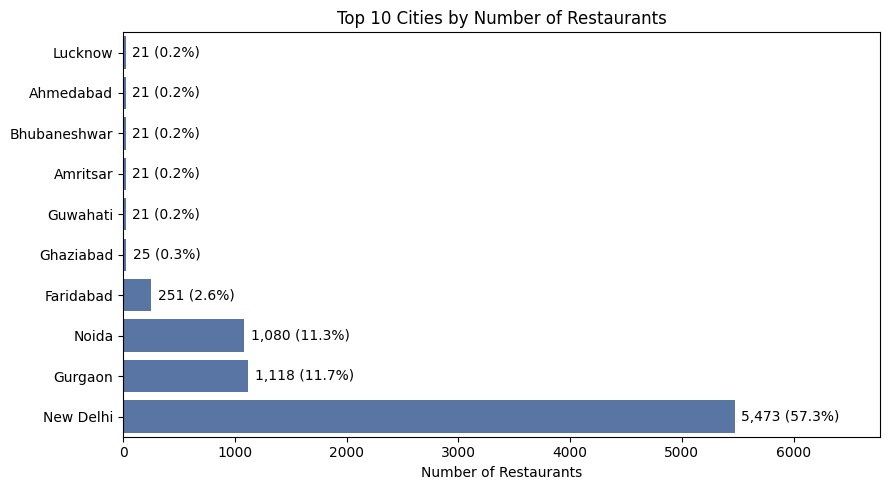

In [43]:
top10 = city_counts.head(10).sort_values()

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=top10.values, y=top10.index, color="#4C72B0")
for i, v in enumerate(top10.values):
    ax.text(v + 60, i, f"{v:,} ({v / len(df) * 100:.1f}%)", va="center")
plt.xlim(0, top10.max() + 1300)
plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 4. Average Rating per City

Two versions of the average are calculated so the effect of unrated
restaurants is visible:

- **All listings:** literal average of `Aggregate rating`, including zeros.
- **Rated only:** excludes restaurants with rating `0` (the fairer measure of
  dining quality).

In [44]:
avg_all = df.groupby("City")["Aggregate rating"].agg(Avg_Rating_All="mean", Restaurants="count")

rated_df = df[df["Aggregate rating"] > 0]
avg_rated = rated_df.groupby("City")["Aggregate rating"].agg(Avg_Rating_Rated="mean", Rated_Restaurants="count")

city_stats = avg_all.join(avg_rated).round(2)
city_stats["Rated_Restaurants"] = city_stats["Rated_Restaurants"].fillna(0).astype(int)
city_stats = city_stats.sort_values("Restaurants", ascending=False)
city_stats.head(10)

,Avg_Rating_All,Restaurants,Avg_Rating_Rated,Rated_Restaurants
City,,,,
New Delhi,2.44,5473,3.30,4048
Gurgaon,2.65,1118,3.33,890
Noida,2.04,1080,3.16,696
Faridabad,1.87,251,3.10,151
Ghaziabad,2.85,25,3.10,23
Bhubaneshwar,3.98,21,3.98,21
Lucknow,4.20,21,4.20,21
Guwahati,4.19,21,4.19,21
Ahmedabad,4.16,21,4.16,21


In [45]:
print("Cities with no rated restaurant at all:", city_stats["Avg_Rating_Rated"].isna().sum())
print(city_stats[city_stats["Avg_Rating_Rated"].isna()].index.tolist())

Cities with no rated restaurant at all: 0
[]


## 5. City with the Highest Average Rating

A raw ranking is misleading: cities with only 1–4 restaurants can top the list
purely by chance. Both views are shown below.

In [46]:
print("Highest average rating, no minimum sample size:")
city_stats.sort_values("Avg_Rating_Rated", ascending=False).head(5)

Highest average rating, no minimum sample size:


,Avg_Rating_All,Restaurants,Avg_Rating_Rated,Rated_Restaurants
City,,,,
Inner City,4.90,2,4.90,2
Quezon City,4.80,1,4.80,1
Makati City,4.65,2,4.65,2
Pasig City,4.63,3,4.63,3
Mandaluyong City,4.62,4,4.62,4


Cities such as *Inner City* (2 restaurants) or *Quezon City* (1 restaurant)
appear at the top, but a single restaurant cannot represent a city. A minimum
sample size of **20 rated restaurants** is applied for a reliable ranking.

In [47]:
MIN_RATED = 20
reliable = city_stats[city_stats["Rated_Restaurants"] >= MIN_RATED].sort_values("Avg_Rating_Rated", ascending=False)

print(f"Cities meeting the threshold: {len(reliable)} of {len(city_stats)}")
reliable.head(10)

Cities meeting the threshold: 71 of 141


,Avg_Rating_All,Restaurants,Avg_Rating_Rated,Rated_Restaurants
City,,,,
London,4.54,20,4.54,20
Orlando,4.47,20,4.47,20
Tampa Bay,4.41,20,4.41,20
Rest of Hawaii,4.41,20,4.41,20
Bangalore,4.38,20,4.38,20
Dubai,4.37,20,4.37,20
Chennai,4.31,20,4.31,20
Abu Dhabi,4.30,20,4.30,20
Ankara,4.30,20,4.30,20


In [48]:
best_city = reliable.index[0]
best_rating = reliable.iloc[0]["Avg_Rating_Rated"]
print(f"Highest average rating (min {MIN_RATED} rated restaurants): {best_city} — {best_rating:.2f}")

Highest average rating (min 20 rated restaurants): London — 4.54


## 6. Visualization

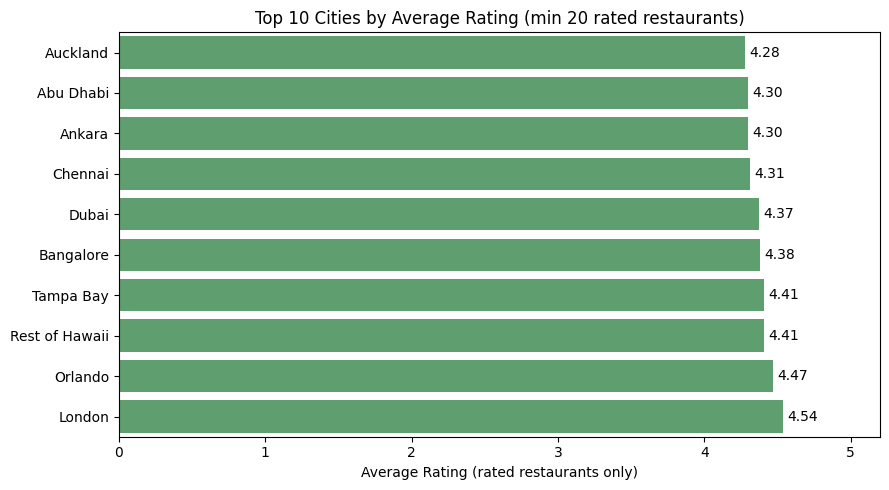

In [49]:
top10_rated = reliable.head(10).sort_values("Avg_Rating_Rated")

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=top10_rated["Avg_Rating_Rated"], y=top10_rated.index, color="#55A868")
for i, v in enumerate(top10_rated["Avg_Rating_Rated"]):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center")
plt.xlim(0, 5.2)
plt.title(f"Top 10 Cities by Average Rating (min {MIN_RATED} rated restaurants)")
plt.xlabel("Average Rating (rated restaurants only)")
plt.ylabel("")
plt.tight_layout()
plt.show()

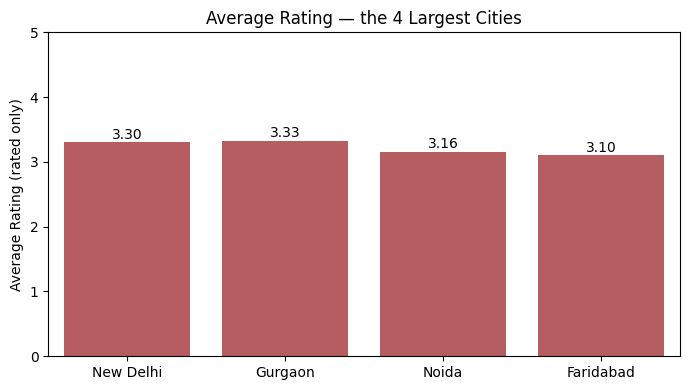

In [50]:
big4 = city_stats.head(4)[["Avg_Rating_Rated"]].reset_index()

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=big4, x="City", y="Avg_Rating_Rated", color="#C44E52")
for i, v in enumerate(big4["Avg_Rating_Rated"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.ylim(0, 5)
plt.title("Average Rating — the 4 Largest Cities")
plt.ylabel("Average Rating (rated only)")
plt.xlabel("")
plt.tight_layout()
plt.show()

## 7. Final Results

In [51]:
task2_result = pd.DataFrame({
    "Question": [
        "City with the most restaurants",
        "Share of dataset in that city",
        "City with the highest average rating (min 20 rated)",
        "Average rating of that city",
    ],
    "Answer": [
        top_city,
        f"{top_city_pct:.2f}%",
        best_city,
        f"{best_rating:.2f}",
    ],
})
task2_result

,Question,Answer
0,City with the most restaurants,New Delhi
1,Share of dataset in that city,57.30%
2,City with the highest average rating (min 20 r...,London
3,Average rating of that city,4.54


## 8. Validation

In [52]:
print("Total restaurants:", len(df))
print("Sum of city counts:", city_counts.sum())
print("Counts match:", len(df) == city_counts.sum())
print("Rated + unrated = total:", len(rated_df) + unrated == len(df))
print("Overall average rating (all):", round(df["Aggregate rating"].mean(), 2))
print("Overall average rating (rated only):", round(rated_df["Aggregate rating"].mean(), 2))

Total restaurants: 9551
Sum of city counts: 9551
Counts match: True
Rated + unrated = total: True
Overall average rating (all): 2.67
Overall average rating (rated only): 3.44


### Business Insights

- **New Delhi** has the most restaurants by far: **5,473 listings (57.30%)** of
  the whole dataset. Together with **Gurgaon (1,118)** and **Noida (1,080)**,
  the Delhi NCR region accounts for roughly 80% of all listings, so the dataset
  is heavily NCR-centric.
- **London** has the highest average rating among cities with at least 20 rated
  restaurants (**4.54**), followed by Orlando (4.47), Tampa Bay and Rest of
  Hawaii (tied at 4.41) and Bangalore (4.38).
- Without a minimum sample size, tiny cities (Inner City, Quezon City, Makati
  City) top the ranking with only 1–3 restaurants, which is not a trustworthy
  conclusion.
- The largest cities are **not** the best rated. Among rated restaurants,
  Gurgaon (3.33), New Delhi (3.30), Noida (3.16) and Faridabad (3.10) all sit
  well below the leading cities.
- **Unrated restaurants distort city averages.** Including zeros, New Delhi
  falls to 2.44, Noida to 2.04 and Faridabad to 1.87, because many listings
  simply have no rating yet. Excluding them gives a fairer picture.
- **Caution:** the top-rated cities each have only about 20 restaurants in the
  dataset, so their ranking is indicative rather than definitive, unlike the
  large NCR cities where averages rest on hundreds or thousands of listings.